In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
from warnings import filterwarnings
filterwarnings('ignore')
pd.set_option('display.max_rows',10)

In [ ]:
df = pd.read_csv('Quikr car price prediction.csv')
df

,name,company,year,Price,kms_driven,fuel_type
0,Hyundai Santro Xing XO eRLX Euro III,Hyundai,2007,"80,000","45,000 kms",Petrol
1,Mahindra Jeep CL550 MDI,Mahindra,2006,"4,25,000",40 kms,Diesel
2,Maruti Suzuki Alto 800 Vxi,Maruti,2018,Ask For Price,"22,000 kms",Petrol
3,Hyundai Grand i10 Magna 1.2 Kappa VTVT,Hyundai,2014,"3,25,000","28,000 kms",Petrol
4,Ford EcoSport Titanium 1.5L TDCi,Ford,2014,"5,75,000","36,000 kms",Diesel
...,...,...,...,...,...,...
887,Ta,Tara,zest,"3,10,000",NaN,NaN
888,Tata Zest XM Diesel,Tata,2018,"2,60,000","27,000 kms",Diesel
889,Mahindra Quanto C8,Mahindra,2013,"3,90,000","40,000 kms",Diesel
890,Honda Amaze 1.2 E i VTEC,Honda,2014,"1,80,000",Petrol,NaN


In [ ]:
df.shape

(892, 6)

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 892 entries, 0 to 891
Data columns (total 6 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   name        892 non-null    object
 1   company     892 non-null    object
 2   year        892 non-null    object
 3   Price       892 non-null    object
 4   kms_driven  840 non-null    object
 5   fuel_type   837 non-null    object
dtypes: object(6)
memory usage: 41.9+ KB


In [ ]:
for i in df.columns:
    print(i)
    print(df[i].unique())
    print(df[i].nunique())
    print()

name
['Hyundai Santro Xing XO eRLX Euro III' 'Mahindra Jeep CL550 MDI'
 'Maruti Suzuki Alto 800 Vxi' 'Hyundai Grand i10 Magna 1.2 Kappa VTVT'
 'Ford EcoSport Titanium 1.5L TDCi' 'Ford Figo' 'Hyundai Eon'
 'Ford EcoSport Ambiente 1.5L TDCi' 'Maruti Suzuki Alto K10 VXi AMT'
 'Skoda Fabia Classic 1.2 MPI' 'Maruti Suzuki Stingray VXi'
 'Hyundai Elite i20 Magna 1.2' 'Mahindra Scorpio SLE BS IV' 'Audi A8'
 'Audi Q7' 'Mahindra Scorpio S10' 'Maruti Suzuki Alto 800'
 'Hyundai i20 Sportz 1.2' 'Maruti Suzuki Alto 800 Lx'
 'Maruti Suzuki Vitara Brezza ZDi' 'Maruti Suzuki Alto LX'
 'Mahindra Bolero DI' 'Maruti Suzuki Swift Dzire ZDi'
 'Mahindra Scorpio S10 4WD' 'Maruti Suzuki Swift Vdi BSIII'
 'Maruti Suzuki Wagon R VXi BS III' 'Maruti Suzuki Wagon R VXi Minor'
 'Toyota Innova 2.0 G 8 STR BS IV' 'Renault Lodgy 85 PS RXL'
 'Skoda Yeti Ambition 2.0 TDI CR 4x2' 'Maruti Suzuki Baleno Delta 1.2'
 'Renault Duster 110 PS RxZ Diesel Plus' 'Renault Duster 85 PS RxE Diesel'
 'Honda City 1.5 S MT' 'Maruti Suz

In [ ]:
df[df.duplicated()]

,name,company,year,Price,kms_driven,fuel_type
14,Hyundai Santro Xing XO eRLX Euro III,Hyundai,2007,"80,000","45,000 kms",Petrol
15,Mahindra Jeep CL550 MDI,Mahindra,2006,"4,25,000",40 kms,Diesel
20,Mahindra Scorpio S10,Mahindra,2016,"3,50,000","43,000 kms",Diesel
24,Hyundai i20 Sportz 1.2,Hyundai,2012,"1,00,000","55,000 kms",Petrol
25,Hyundai i20 Sportz 1.2,Hyundai,2012,"1,00,000","55,000 kms",Petrol
...,...,...,...,...,...,...
626,Tata Sumo Gold EX BS IV,Tata,2012,"2,10,000","75,000 kms",Diesel
641,Maruti Suzuki Swift VDi BS IV,Maruti,2012,"2,80,000","48,006 kms",Diesel
727,Mahindra Scorpio S4,Mahindra,2015,"8,65,000","30,000 kms",Diesel
861,Hyundai Getz Prime 1.3 GLX,Hyundai,2009,"1,15,000","20,000 kms",Petrol


In [ ]:
df.drop_duplicates(keep= 'first',inplace= True,ignore_index = True)

In [ ]:
df.shape

(798, 6)

### Cleaning the Dataset

In [ ]:
df.year.unique()

array(['2007', '2006', '2018', '2014', '2015', '2012', '2013', '2016',
       '2010', '2017', '2008', '2011', '2019', '2009', '2005', '2000',
       '...', '150k', 'TOUR', '2003', 'r 15', '2004', 'Zest', '/-Rs',
       'sale', '1995', 'ara)', '2002', 'SELL', '2001', 'tion', 'odel',
       '2 bs', 'arry', 'Eon', 'o...', 'ture', 'emi', 'car', 'able', 'no.',
       'd...', 'SALE', 'digo', 'sell', 'd Ex', 'n...', 'e...', 'D...',
       ', Ac', 'go .', 'k...', 'o c4', 'zire', 'cent', 'Sumo', 'cab',
       't xe', 'EV2', 'r...', 'zest'], dtype=object)

In [ ]:
df1 = df.copy(deep=True)

In [ ]:
df = df[df.year.str.isnumeric()]
df.head(20)

,name,company,year,Price,kms_driven,fuel_type
0,Hyundai Santro Xing XO eRLX Euro III,Hyundai,2007,"80,000","45,000 kms",Petrol
1,Mahindra Jeep CL550 MDI,Mahindra,2006,"4,25,000",40 kms,Diesel
2,Maruti Suzuki Alto 800 Vxi,Maruti,2018,Ask For Price,"22,000 kms",Petrol
3,Hyundai Grand i10 Magna 1.2 Kappa VTVT,Hyundai,2014,"3,25,000","28,000 kms",Petrol
4,Ford EcoSport Titanium 1.5L TDCi,Ford,2014,"5,75,000","36,000 kms",Diesel
...,...,...,...,...,...,...
15,Audi Q7,Audi,2014,"5,00,000","16,934 kms",Diesel
16,Mahindra Scorpio S10,Mahindra,2016,"3,50,000","43,000 kms",Diesel
17,Maruti Suzuki Alto 800,Maruti,2014,"1,60,000","35,550 kms",Petrol
18,Mahindra Scorpio S10,Mahindra,2016,"3,10,000","39,522 kms",Diesel


In [ ]:
df.reset_index(drop = True,inplace=True)
df

,name,company,year,Price,kms_driven,fuel_type
0,Hyundai Santro Xing XO eRLX Euro III,Hyundai,2007,"80,000","45,000 kms",Petrol
1,Mahindra Jeep CL550 MDI,Mahindra,2006,"4,25,000",40 kms,Diesel
2,Maruti Suzuki Alto 800 Vxi,Maruti,2018,Ask For Price,"22,000 kms",Petrol
3,Hyundai Grand i10 Magna 1.2 Kappa VTVT,Hyundai,2014,"3,25,000","28,000 kms",Petrol
4,Ford EcoSport Titanium 1.5L TDCi,Ford,2014,"5,75,000","36,000 kms",Diesel
...,...,...,...,...,...,...
744,Toyota Corolla Altis,Toyota,2009,"3,00,000","1,32,000 kms",Petrol
745,Tata Zest XM Diesel,Tata,2018,"2,60,000","27,000 kms",Diesel
746,Mahindra Quanto C8,Mahindra,2013,"3,90,000","40,000 kms",Diesel
747,Honda Amaze 1.2 E i VTEC,Honda,2014,"1,80,000",Petrol,NaN


In [ ]:
798-749

49

In [ ]:
df

,name,company,year,Price,kms_driven,fuel_type
0,Hyundai Santro Xing XO eRLX Euro III,Hyundai,2007,"80,000","45,000 kms",Petrol
1,Mahindra Jeep CL550 MDI,Mahindra,2006,"4,25,000",40 kms,Diesel
2,Maruti Suzuki Alto 800 Vxi,Maruti,2018,Ask For Price,"22,000 kms",Petrol
3,Hyundai Grand i10 Magna 1.2 Kappa VTVT,Hyundai,2014,"3,25,000","28,000 kms",Petrol
4,Ford EcoSport Titanium 1.5L TDCi,Ford,2014,"5,75,000","36,000 kms",Diesel
...,...,...,...,...,...,...
744,Toyota Corolla Altis,Toyota,2009,"3,00,000","1,32,000 kms",Petrol
745,Tata Zest XM Diesel,Tata,2018,"2,60,000","27,000 kms",Diesel
746,Mahindra Quanto C8,Mahindra,2013,"3,90,000","40,000 kms",Diesel
747,Honda Amaze 1.2 E i VTEC,Honda,2014,"1,80,000",Petrol,NaN


In [ ]:
df.year.dtype

dtype('O')

In [ ]:
df['year'] = df.year.astype('int')

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 749 entries, 0 to 748
Data columns (total 6 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   name        749 non-null    object
 1   company     749 non-null    object
 2   year        749 non-null    int64 
 3   Price       749 non-null    object
 4   kms_driven  748 non-null    object
 5   fuel_type   745 non-null    object
dtypes: int64(1), object(5)
memory usage: 35.2+ KB


### Price

In [ ]:
df.Price.head()

0           80,000
1         4,25,000
2    Ask For Price
3         3,25,000
4         5,75,000
Name: Price, dtype: object

In [ ]:
'80,000'.replace(',','')

'80000'

In [ ]:
df = df[df.Price.str.replace(',','').str.isnumeric()]
df

,name,company,year,Price,kms_driven,fuel_type
0,Hyundai Santro Xing XO eRLX Euro III,Hyundai,2007,"80,000","45,000 kms",Petrol
1,Mahindra Jeep CL550 MDI,Mahindra,2006,"4,25,000",40 kms,Diesel
3,Hyundai Grand i10 Magna 1.2 Kappa VTVT,Hyundai,2014,"3,25,000","28,000 kms",Petrol
4,Ford EcoSport Titanium 1.5L TDCi,Ford,2014,"5,75,000","36,000 kms",Diesel
6,Ford Figo,Ford,2012,"1,75,000","41,000 kms",Diesel
...,...,...,...,...,...,...
744,Toyota Corolla Altis,Toyota,2009,"3,00,000","1,32,000 kms",Petrol
745,Tata Zest XM Diesel,Tata,2018,"2,60,000","27,000 kms",Diesel
746,Mahindra Quanto C8,Mahindra,2013,"3,90,000","40,000 kms",Diesel
747,Honda Amaze 1.2 E i VTEC,Honda,2014,"1,80,000",Petrol,NaN


In [ ]:
df.reset_index(drop= True,inplace=True)

In [ ]:
df['Price'] = df.Price.str.replace(',','')

In [ ]:
df

,name,company,year,Price,kms_driven,fuel_type
0,Hyundai Santro Xing XO eRLX Euro III,Hyundai,2007,80000,"45,000 kms",Petrol
1,Mahindra Jeep CL550 MDI,Mahindra,2006,425000,40 kms,Diesel
2,Hyundai Grand i10 Magna 1.2 Kappa VTVT,Hyundai,2014,325000,"28,000 kms",Petrol
3,Ford EcoSport Titanium 1.5L TDCi,Ford,2014,575000,"36,000 kms",Diesel
4,Ford Figo,Ford,2012,175000,"41,000 kms",Diesel
...,...,...,...,...,...,...
722,Toyota Corolla Altis,Toyota,2009,300000,"1,32,000 kms",Petrol
723,Tata Zest XM Diesel,Tata,2018,260000,"27,000 kms",Diesel
724,Mahindra Quanto C8,Mahindra,2013,390000,"40,000 kms",Diesel
725,Honda Amaze 1.2 E i VTEC,Honda,2014,180000,Petrol,NaN


In [ ]:
df['Price'] = df.Price.astype('int')

In [ ]:
df

,name,company,year,Price,kms_driven,fuel_type
0,Hyundai Santro Xing XO eRLX Euro III,Hyundai,2007,80000,"45,000 kms",Petrol
1,Mahindra Jeep CL550 MDI,Mahindra,2006,425000,40 kms,Diesel
2,Hyundai Grand i10 Magna 1.2 Kappa VTVT,Hyundai,2014,325000,"28,000 kms",Petrol
3,Ford EcoSport Titanium 1.5L TDCi,Ford,2014,575000,"36,000 kms",Diesel
4,Ford Figo,Ford,2012,175000,"41,000 kms",Diesel
...,...,...,...,...,...,...
722,Toyota Corolla Altis,Toyota,2009,300000,"1,32,000 kms",Petrol
723,Tata Zest XM Diesel,Tata,2018,260000,"27,000 kms",Diesel
724,Mahindra Quanto C8,Mahindra,2013,390000,"40,000 kms",Diesel
725,Honda Amaze 1.2 E i VTEC,Honda,2014,180000,Petrol,NaN


### KMS

In [ ]:
'1,32,000 kms'.replace(',','').split()[0]

'132000'

In [ ]:
df['kms_driven'] = df.kms_driven.apply(lambda x: x.replace(',','').split()[0])

In [ ]:
df.shape

(727, 6)

In [ ]:
df = df[df['kms_driven'].str.isnumeric()]

In [ ]:
df['kms_driven'] = df['kms_driven'].astype(int)

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 725 entries, 0 to 724
Data columns (total 6 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   name        725 non-null    object
 1   company     725 non-null    object
 2   year        725 non-null    int64 
 3   Price       725 non-null    int64 
 4   kms_driven  725 non-null    int64 
 5   fuel_type   724 non-null    object
dtypes: int64(3), object(3)
memory usage: 39.6+ KB


In [ ]:
df.isnull().sum()

name          0
company       0
year          0
Price         0
kms_driven    0
fuel_type     1
dtype: int64

In [ ]:
df[df.isnull().any(axis = 1)]

,name,company,year,Price,kms_driven,fuel_type
106,Toyota Corolla,Toyota,2009,275000,26000,NaN


In [ ]:
df[(df.company == 'Toyota') & (df.fuel_type.isnull())]

,name,company,year,Price,kms_driven,fuel_type
106,Toyota Corolla,Toyota,2009,275000,26000,NaN


In [ ]:
df.fuel_type.fillna('Diesel',inplace=True)

In [ ]:
df[df.company == 'Toyota'].fuel_type.mode()

0    Diesel
Name: fuel_type, dtype: object

In [ ]:
df[df.company == 'Toyota'].fuel_type.value_counts()

fuel_type
Diesel    19
Petrol    16
Name: count, dtype: int64

In [ ]:
df.isnull().sum()

name          0
company       0
year          0
Price         0
kms_driven    0
fuel_type     0
dtype: int64

In [ ]:
df

,name,company,year,Price,kms_driven,fuel_type
0,Hyundai Santro Xing XO eRLX Euro III,Hyundai,2007,80000,45000,Petrol
1,Mahindra Jeep CL550 MDI,Mahindra,2006,425000,40,Diesel
2,Hyundai Grand i10 Magna 1.2 Kappa VTVT,Hyundai,2014,325000,28000,Petrol
3,Ford EcoSport Titanium 1.5L TDCi,Ford,2014,575000,36000,Diesel
4,Ford Figo,Ford,2012,175000,41000,Diesel
...,...,...,...,...,...,...
720,Maruti Suzuki Ritz VXI ABS,Maruti,2011,270000,50000,Petrol
721,Tata Indica V2 DLE BS III,Tata,2009,110000,30000,Diesel
722,Toyota Corolla Altis,Toyota,2009,300000,132000,Petrol
723,Tata Zest XM Diesel,Tata,2018,260000,27000,Diesel


<Axes: xlabel='Price', ylabel='Density'>

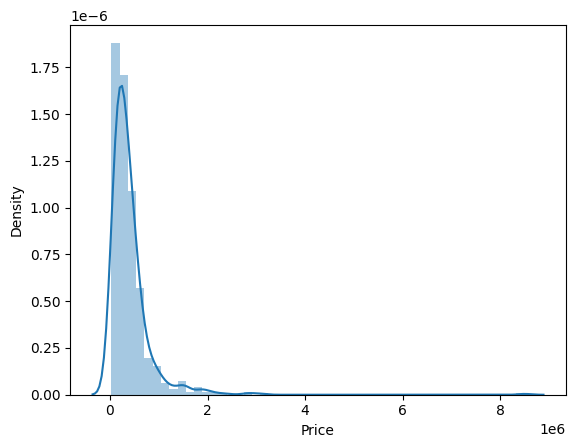

In [ ]:
sns.distplot(df.Price)

<Axes: xlabel='Price'>

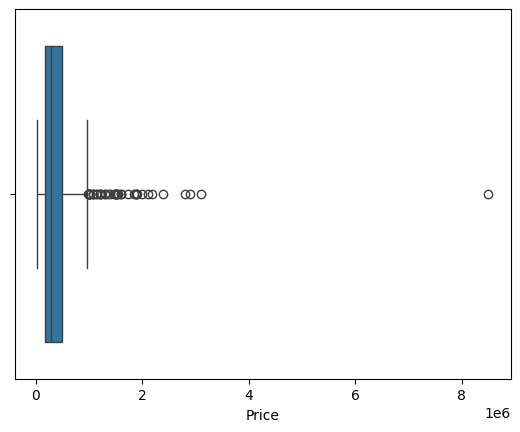

In [ ]:
sns.boxplot(x =df.Price)

In [ ]:
df[df.Price>4000000]

,name,company,year,Price,kms_driven,fuel_type
448,Mahindra XUV500 W6,Mahindra,2014,8500003,45000,Diesel


In [ ]:
df[(df.company == 'Mahindra') & (df.name == 'Mahindra XUV500 W6')]

,name,company,year,Price,kms_driven,fuel_type
376,Mahindra XUV500 W6,Mahindra,2013,548900,49800,Diesel
448,Mahindra XUV500 W6,Mahindra,2014,8500003,45000,Diesel
471,Mahindra XUV500 W6,Mahindra,2013,549900,52800,Diesel


In [ ]:
df.loc[448,'Price'] = 850000

In [ ]:
df[(df.company == 'Mahindra') & (df.name == 'Mahindra XUV500 W6')]

,name,company,year,Price,kms_driven,fuel_type
376,Mahindra XUV500 W6,Mahindra,2013,548900,49800,Diesel
448,Mahindra XUV500 W6,Mahindra,2014,850000,45000,Diesel
471,Mahindra XUV500 W6,Mahindra,2013,549900,52800,Diesel


In [ ]:
df[['Price','kms_driven','year']].corr()

,Price,kms_driven,year
Price,1.000000,-0.156843,0.363998
kms_driven,-0.156843,1.000000,-0.249949
year,0.363998,-0.249949,1.000000


In [ ]:
a = df.groupby("company")['Price'].mean().reset_index()
a

,company,Price
0,Audi,1.554700e+06
1,BMW,1.049875e+06
2,Chevrolet,1.968454e+05
3,Datsun,2.591663e+05
4,Fiat,1.215000e+05
...,...,...
20,Skoda,2.764488e+05
21,Tata,1.969025e+05
22,Toyota,4.958570e+05
23,Volkswagen,4.211762e+05


In [ ]:
a['Price'] = a.Price.round()

In [ ]:
a

,company,Price
0,Audi,1554700.0
1,BMW,1049875.0
2,Chevrolet,196845.0
3,Datsun,259166.0
4,Fiat,121500.0
...,...,...
20,Skoda,276449.0
21,Tata,196903.0
22,Toyota,495857.0
23,Volkswagen,421176.0


In [ ]:
df[df.company == 'Audi']['Price'].mean()

np.float64(1554700.0)

In [ ]:
df.fuel_type.unique()

array(['Petrol', 'Diesel', 'LPG'], dtype=object)

In [ ]:
df.fuel_type

0      Petrol
1      Diesel
2      Petrol
3      Diesel
4      Diesel
        ...  
720    Petrol
721    Diesel
722    Petrol
723    Diesel
724    Diesel
Name: fuel_type, Length: 725, dtype: object

In [ ]:
df.to_csv('cleaned_file.csv',index= False)

In [ ]:
sns.distplot(df.Price)

In [ ]:
sns.distplot(np.log(df.Price))

In [ ]:
sns.boxplot(x =df.Price)

In [ ]:
df.Price.max()

In [ ]:
df.groupby('fuel_type')['Price'].max()

In [ ]:
df[df.company == 'Toyota']['fuel_type'].mode()

In [ ]:
df.shape

In [ ]:
798-749

In [ ]:
'2023'.isnumeric()